# Interior profiles of the Kepler-80 planets

This notebook runs `paleos-interior` from a single planet to the full output for a measured mass and radius, with the Kepler-80 system as the example. Every planet is a two-layer interior, an iron core under an MgSiO3 mantle, in hydrostatic equilibrium on an adiabat, with material properties from the PALEOS lookup tables (Attia et al. 2026, A&A 713, A225).

Install the package with the plotting extras:

```bash
pip install "paleos-interior[examples] @ git+https://github.com/maraattia/PALEOSInterior.git"
```

The first call to `load_tables` downloads the PALEOS 1.3.0 iron and MgSiO3 tables from Zenodo (about 125 MB) and caches them, so later sessions start at once. The full notebook runs in about two minutes on a laptop, plus the download on first use.

In [1]:
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize

import paleos_interior as pi
from paleos_interior.constants import M_EARTH, R_EARTH

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
T_CMAP = LinearSegmentedColormap.from_list('T_pot', ['#86b6ef', '#0d366b'])
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.6,
    'lines.linewidth': 2.0,
})
print(f'paleos-interior {pi.__version__}')

paleos-interior 1.0.0


In [2]:
tables = pi.load_tables()
print(*tables.provenance(), sep='\n')

PALEOS tables 1.3.0, doi:10.5281/zenodo.22776069
paleos_iron_eos_table_pt.dat md5 259a2267dcf58af3b2c4dd389105b597
paleos_mgsio3_eos_table_pt.dat md5 1f75d518bf192e66b94ec0bda190ada7


## 1. One planet at fixed composition and temperature

`integrate` builds one planet from its mass (Earth masses), its core mass fraction (CMF), and the mantle potential temperature $T_\mathrm{pot}$, the temperature the mantle adiabat would have at 1 bar. It finds the radius at which the mass integrated inward from the surface vanishes at the center and returns a `Profile` ordered from the surface to $r$ = 5 km. Arrays are attributes in SI units (`r`, `m`, `g`, `P`, `T`, `rho`, ..., see the README for the full list), and the core-mantle boundary (CMB) radius appears twice, once with mantle and once with core properties.

As a first case, take an Earth-mass planet with Earth's core mass fraction, 0.325, and $T_\mathrm{pot}$ = 1600 K.

In [3]:
t0 = time.perf_counter()
earth = pi.integrate(1.0, 0.325, 1600.0, tables=tables)
print(f'integrate: {time.perf_counter() - t0:.1f} s')
print(f'R      = {earth.radius / 1e3:.0f} km = {earth.radius / R_EARTH:.4f} Earth radii')
print(f'R_cmb  = {earth.R_cmb / 1e3:.0f} km')
print(f'P_cmb  = {earth.P_cmb / 1e9:.0f} GPa, T_cmb = {earth.T_cmb:.0f} K')
print(f'P_5km  = {earth.P_center / 1e9:.0f} GPa, T_5km = {earth.T_center:.0f} K')

integrate: 0.7 s
R      = 6334 km = 0.9931 Earth radii
R_cmb  = 3309 km
P_cmb  = 147 GPa, T_cmb = 2647 K
P_5km  = 421 GPa, T_5km = 3375 K


The radius is 6334 km, 0.6% below Earth's mean radius of 6371 km. The model core is pure iron and the mantle pure MgSiO3, while Earth's core holds light elements that lower both its density and its melting point. The whole model core is therefore solid hcp iron, where Earth's outer core is liquid. The phase sequence of each layer, from the surface inward:

In [4]:
def phase_table(profile):
    # One row per contiguous run of a phase, from the surface inward.
    layer, phase = profile.layer, profile.phase
    edges = np.flatnonzero((layer[1:] != layer[:-1]) | (phase[1:] != phase[:-1])) + 1
    rows = []
    for a, b in zip(np.r_[0, edges], np.r_[edges, len(phase)]):
        rows.append({
            'layer': layer[a],
            'phase': phase[a],
            'r_top [km]': profile.r[a] / 1e3,
            'r_bottom [km]': profile.r[b - 1] / 1e3,
            'P_top [GPa]': profile.P[a] / 1e9,
            'P_bottom [GPa]': profile.P[b - 1] / 1e9,
        })
    return pd.DataFrame(rows).round(1)


phase_table(earth)

,layer,phase,r_top [km],r_bottom [km],P_top [GPa],P_bottom [GPa]
0,mantle,solid-en,6334.4,6087.0,0.0,7.8
1,mantle,solid-hpcen,6080.7,5972.8,8.0,11.7
2,mantle,solid-brg,5966.5,3562.5,11.9,130.8
3,mantle,solid-ppv,3556.2,3308.8,131.2,146.8
4,core,solid-epsilon-hcp,3308.8,5.0,146.8,421.4


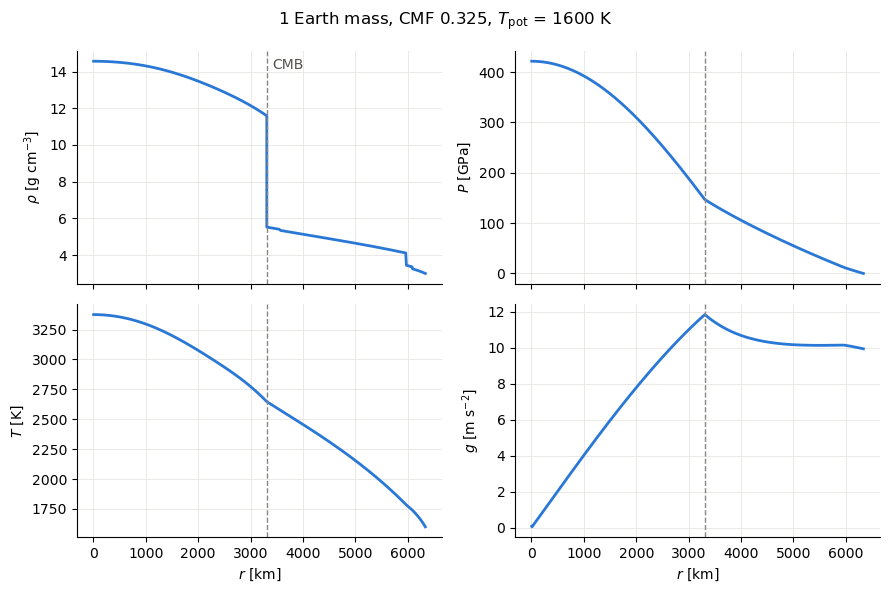

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
panels = [
    ('rho', 1e3, r'$\rho$ [g cm$^{-3}$]'),
    ('P', 1e9, '$P$ [GPa]'),
    ('T', 1.0, '$T$ [K]'),
    ('g', 1.0, '$g$ [m s$^{-2}$]'),
]
for ax, (key, scale, label) in zip(axes.flat, panels):
    ax.plot(earth.r / 1e3, getattr(earth, key) / scale, color=BLUE)
    ax.axvline(earth.R_cmb / 1e3, color='#898781', lw=1, ls='--')
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel('$r$ [km]')
axes[0, 0].annotate('CMB', (earth.R_cmb / 1e3, 0.97), xycoords=('data', 'axes fraction'),
                    xytext=(4, 0), textcoords='offset points', color='#52514e', va='top')
fig.suptitle('1 Earth mass, CMF 0.325, $T_\\mathrm{pot}$ = 1600 K')
fig.tight_layout()

## 2. The Kepler-80 planets

MacDonald, Shakespeare & Ragozzine (2021, AJ 162, 114) fit the Kepler light curve of Kepler-80 with a photodynamical model and give radii for all six planets and masses for five (their Table 1). The values are posterior medians with the 16th and 84th percentiles as lower and upper uncertainties. Kepler-80 f does not interact dynamically with the other planets, so its mass is unconstrained, and the authors caution that the mass they fit for Kepler-80 g is likely over-fit. Both are left out here.

The package reads radii in units of the IAU 2015 nominal equatorial Earth radius, 6378.1 km. The paper does not state which Earth radius it uses, but the difference from the mean radius (0.11%) is small next to the 3% radius uncertainties.

Masses and radii are passed as `(value, sigma)` or `(value, sigma_minus, sigma_plus)`.

In [6]:
PLANETS = {
    'Kepler-80 d': {'mass': (5.95, 0.60, 0.65), 'radius': (1.309, 0.032, 0.036)},
    'Kepler-80 e': {'mass': (2.97, 0.65, 0.76), 'radius': (1.330, 0.038, 0.039)},
    'Kepler-80 b': {'mass': (3.50, 0.57, 0.63), 'radius': (2.367, 0.052, 0.055)},
    'Kepler-80 c': {'mass': (3.49, 0.57, 0.63), 'radius': (2.507, 0.058, 0.061)},
}


def bulk_density(mass, radius):
    # g cm-3, from masses and radii in Earth units
    return 1e-3 * mass * M_EARTH / (4.0 / 3.0 * np.pi * (radius * R_EARTH) ** 3)


pd.DataFrame([
    {
        'planet': name,
        'M [M_earth]': p['mass'][0],
        'sigma_M -/+': f"{p['mass'][1]} / {p['mass'][2]}",
        'R [R_earth]': p['radius'][0],
        'sigma_R -/+': f"{p['radius'][1]} / {p['radius'][2]}",
        'rho [g cm-3]': round(bulk_density(p['mass'][0], p['radius'][0]), 2),
    }
    for name, p in PLANETS.items()
])

,planet,M [M_earth],sigma_M -/+,R [R_earth],sigma_R -/+,rho [g cm-3]
0,Kepler-80 d,5.95,0.6 / 0.65,1.309,0.032 / 0.036,14.58
1,Kepler-80 e,2.97,0.65 / 0.76,1.330,0.038 / 0.039,6.94
2,Kepler-80 b,3.50,0.57 / 0.63,2.367,0.052 / 0.055,1.45
3,Kepler-80 c,3.49,0.57 / 0.63,2.507,0.058 / 0.061,1.22


The bulk densities computed from the nominal values are close to the paper's own column (14.6, 6.9, 1.45, and 1.22 g cm$^{-3}$ for d, e, b, and c), which comes from the posterior samples. Kepler-80 d is denser than any Earth-like rock and iron mixture of its mass, and b and c are lighter than a rocky planet can be. The next sections show what the model makes of each.

## 3. The degeneracy between temperature and core mass fraction

A hotter mantle is less dense, so at fixed mass and core mass fraction the planet is larger. A measured radius can therefore be met by a cold planet with a small core or a hot planet with a large one. `compatible_line` traces this degeneracy: at `n_line` values of $T_\mathrm{pot}$ across the requested range, it solves for the CMF that reproduces the radius. The $T_\mathrm{pot}$ range is a required argument, because the plausible range depends on the planet's age and irradiation. This notebook uses 1000 to 4500 K for all planets.

In [7]:
T_POT = (1000.0, 4500.0)
e = PLANETS['Kepler-80 e']

t0 = time.perf_counter()
line_e = pi.compatible_line(e['mass'][0], e['radius'][0], T_POT, tables=tables)
print(f'compatible_line: {time.perf_counter() - t0:.1f} s')

pd.DataFrame({
    'T_pot [K]': line_e.T_pot,
    'CMF': line_e.cmf,
    'R_cmb [km]': line_e.R_cmb / 1e3,
    'P_cmb [GPa]': line_e.P_cmb / 1e9,
    'T_cmb [K]': line_e.T_cmb,
}).round({'T_pot [K]': 0, 'CMF': 4, 'R_cmb [km]': 0, 'P_cmb [GPa]': 1, 'T_cmb [K]': 0})

compatible_line: 5.7 s


,T_pot [K],CMF,R_cmb [km],P_cmb [GPa],T_cmb [K]
0,1000.0,0.3478,4444.0,410.9,2070.0
1,1318.0,0.3584,4496.0,403.2,2775.0
2,1636.0,0.3700,4554.0,394.6,3515.0
3,1955.0,0.3807,4609.0,386.1,4257.0
4,2273.0,0.3932,4673.0,376.5,5009.0
5,2591.0,0.4110,4758.0,364.3,5785.0
6,2909.0,0.4338,4865.0,349.3,6444.0
7,3227.0,0.4739,5066.0,321.2,6896.0
8,3545.0,0.5164,5228.0,297.3,7187.0
9,3864.0,0.6325,5647.0,214.7,6733.0


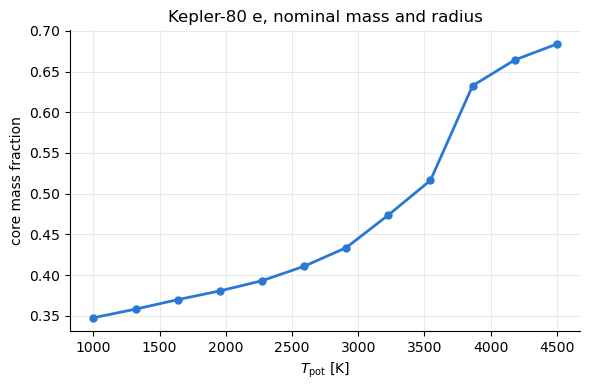

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(line_e.T_pot, line_e.cmf, color=BLUE, marker='o', ms=5)
ax.set_xlabel('$T_\\mathrm{pot}$ [K]')
ax.set_ylabel('core mass fraction')
ax.set_title('Kepler-80 e, nominal mass and radius')
fig.tight_layout()

The CMF of Kepler-80 e rises from 0.35 at 1000 K to 0.68 at 4500 K. The rise is slow while the planet is solid and steepest where its layers melt: the core melts between about 2900 and 3200 K, and most of the mantle between about 3500 and 3900 K. Melt is less dense than the solid, so a molten planet needs more iron to keep the same radius.

## 4. All outputs for a measured mass and radius

`interior_profiles` combines the steps. It solves the line at the nominal mass and radius, then the lines at the two corners of the 1$\sigma$ box with the highest and lowest bulk density, dense $(M + \sigma_M^+,\ R - \sigma_R^-)$ and light $(M - \sigma_M^-,\ R + \sigma_R^+)$. Finally it builds `n_profiles` full profiles spaced evenly in $T_\mathrm{pot}$ along the nominal line. The corner lines bound the range of CMF allowed by the measurement errors. The profiles all sit on the nominal line, so the measurement errors are reported through the envelope and are not propagated into the profiles.

At fixed $T_\mathrm{pot}$, the CMF rises with mass and falls with radius, so the two corners bound the CMF of every mass and radius in the 1$\sigma$ box. For Kepler-80 d and e this holds at every point of a 5 by 5 grid across the box.

In [9]:
results = {}
for name in ('Kepler-80 d', 'Kepler-80 e'):
    t0 = time.perf_counter()
    results[name] = pi.interior_profiles(**PLANETS[name], T_pot=T_POT, n_profiles=10)
    print(f'{name}: {time.perf_counter() - t0:.0f} s')

Kepler-80 d: 36 s


Kepler-80 e: 34 s


Kepler-80 d, dense corner (M = 6.600, R = 1.277): CMF 0.970 to 1.000, T_pot 1000 to 2291 K
Kepler-80 d, light corner (M = 5.350, R = 1.345): CMF 0.771 to 0.924, T_pot 1000 to 4500 K
Kepler-80 e, dense corner (M = 3.730, R = 1.292): CMF 0.636 to 0.851, T_pot 1000 to 4500 K
Kepler-80 e, light corner (M = 2.320, R = 1.369): CMF 0.000 to 0.452, T_pot 1857 to 4500 K


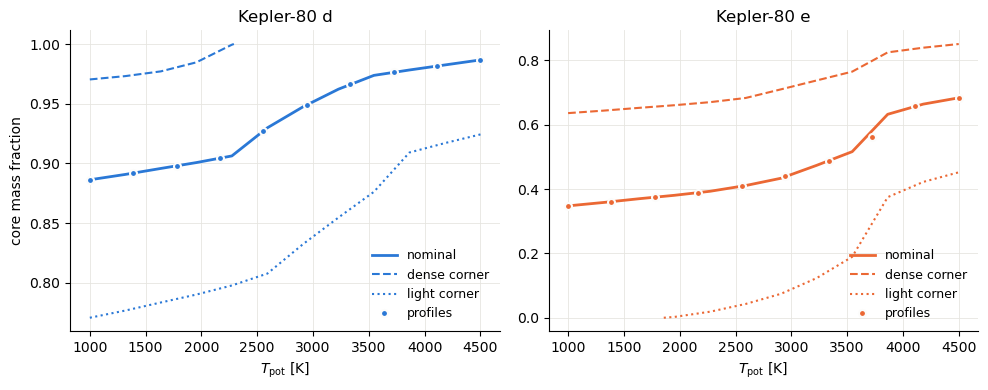

In [10]:
styles = {'dense': ('--', 'dense corner'), 'light': (':', 'light corner')}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, (name, result), color in zip(axes, results.items(), (BLUE, ORANGE)):
    line = result.line
    ax.plot(line.T_pot, line.cmf, color=color, label='nominal')
    for corner, (ls, label) in styles.items():
        cl = result.envelope[corner]
        if cl.solvable:
            ax.plot(cl.T_pot, cl.cmf, color=color, ls=ls, lw=1.5, label=label)
        else:
            ax.plot([], [], color=color, ls=ls, lw=1.5, label=f'{label}: no solution')
    T_samples = [p.T_pot for p in result.profiles]
    ax.plot(T_samples, [p.cmf for p in result.profiles], 'o', color=color, ms=5,
            mec='#fcfcfb', mew=1.5, label='profiles')
    ax.set_title(name)
    ax.set_xlabel('$T_\\mathrm{pot}$ [K]')
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel('core mass fraction')
fig.tight_layout()

for name, result in results.items():
    for corner, cl in result.envelope.items():
        M, R = cl.mass / M_EARTH, cl.radius / R_EARTH
        if cl.solvable:
            lo, hi = cl.T_range
            state = f'CMF {cl.cmf.min():.3f} to {cl.cmf.max():.3f}, T_pot {lo:.0f} to {hi:.0f} K'
        else:
            state = 'no solution'
        print(f'{name}, {corner} corner (M = {M:.3f}, R = {R:.3f}): {state}')

Kepler-80 d needs a core of 89 to 99% of its mass on the nominal line. Its dense corner reaches pure iron near 2300 K and above that is denser than iron allows, so its line stops there. MacDonald et al. (2021) found with the MAGRATHEA structure code that the planet must be at least 92% core by mass. For Kepler-80 e, the light corner has no rocky solution below about 1860 K, because even a pure MgSiO3 planet of that mass is smaller than its radius. The measurement errors on e allow anything from almost no core to 85% iron, a wider range than the temperature alone.

`summary()` returns the scalars of every profile as a dict of SI arrays.

In [11]:
s = results['Kepler-80 e'].summary()
pd.DataFrame({
    'T_pot [K]': s['T_pot'],
    'CMF': s['CMF'],
    'R [R_earth]': s['R'] / R_EARTH,
    'R_cmb [km]': s['R_cmb'] / 1e3,
    'P_cmb [GPa]': s['P_cmb'] / 1e9,
    'T_cmb [K]': s['T_cmb'],
    'P_5km [GPa]': s['P_inner'] / 1e9,
    'T_5km [K]': s['T_inner'],
}).round({'T_pot [K]': 0, 'CMF': 4, 'R [R_earth]': 6, 'R_cmb [km]': 0, 'P_cmb [GPa]': 1,
          'T_cmb [K]': 0, 'P_5km [GPa]': 0, 'T_5km [K]': 0})

,T_pot [K],CMF,R [R_earth],R_cmb [km],P_cmb [GPa],T_cmb [K],P_5km [GPa],T_5km [K]
0,1000.0,0.3478,1.330000,4444.0,410.9,2070.0,1294.0,3078.0
1,1389.0,0.3609,1.330000,4509.0,401.3,2936.0,1301.0,4468.0
2,1778.0,0.3757,1.330000,4583.0,390.4,3859.0,1308.0,6024.0
3,2167.0,0.3882,1.330000,4648.0,380.2,4746.0,1309.0,7580.0
4,2556.0,0.4089,1.330000,4748.0,365.7,5704.0,1317.0,9395.0
5,2944.0,0.4398,1.330000,4903.0,343.9,6491.0,1325.0,11817.0
6,3333.0,0.4863,1.330000,5115.0,314.2,7023.0,1321.0,13785.0
7,3722.0,0.5635,1.329999,5402.0,264.8,7101.0,1373.0,15446.0
8,4111.0,0.6596,1.330001,5751.0,194.6,6901.0,1412.0,17587.0
9,4500.0,0.6837,1.330000,5849.0,178.5,7295.0,1410.0,19501.0


## 5. Radial profiles

Each profile carries the thermodynamic state ($P$, $T$, $\rho$), the table properties ($C_P$, $C_V$, $\alpha$, $\nabla_\mathrm{ad}$), the bulk moduli $K_T$ and $K_S$, the bulk sound speed $V_\phi$, the unrelaxed shear modulus `mu`, the wave speeds $V_P$ and $V_S$, the viscosity `eta`, and the layer and phase labels. `mu` is the infinite-frequency modulus, the parameter of a Maxwell or Andrade body, and is nonzero in liquids. $V_P$ and $V_S$ use the relaxed modulus, which is zero in liquids. The sources of the shear modulus and viscosity laws are listed in the README and in every profile file.

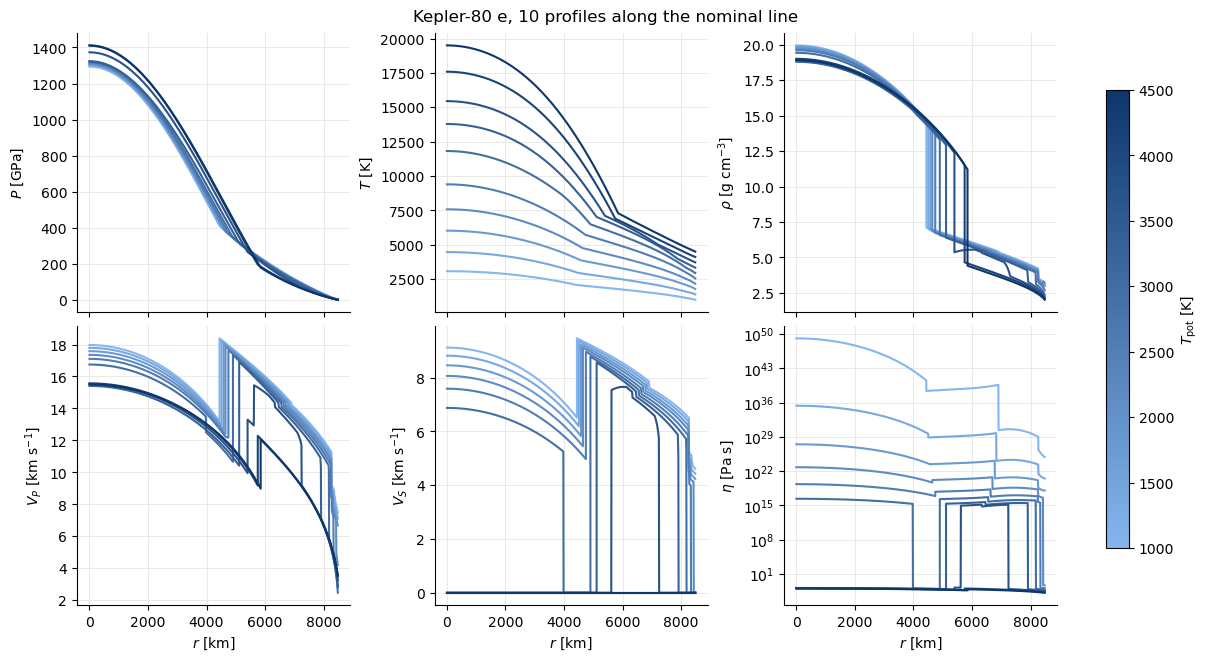

In [12]:
def plot_profiles(result, title):
    norm = Normalize(*result.line.T_range)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, layout='constrained')
    panels = [
        ('P', 1e9, '$P$ [GPa]', 'linear'),
        ('T', 1.0, '$T$ [K]', 'linear'),
        ('rho', 1e3, r'$\rho$ [g cm$^{-3}$]', 'linear'),
        ('V_P', 1e3, '$V_P$ [km s$^{-1}$]', 'linear'),
        ('V_S', 1e3, '$V_S$ [km s$^{-1}$]', 'linear'),
        ('eta', 1.0, r'$\eta$ [Pa s]', 'log'),
    ]
    for p in result.profiles:
        for ax, (key, scale, label, yscale) in zip(axes.flat, panels):
            ax.plot(p.r / 1e3, getattr(p, key) / scale, color=T_CMAP(norm(p.T_pot)), lw=1.5)
            ax.set_ylabel(label)
            ax.set_yscale(yscale)
    for ax in axes[1]:
        ax.set_xlabel('$r$ [km]')
    sm = plt.cm.ScalarMappable(norm=norm, cmap=T_CMAP)
    fig.colorbar(sm, ax=axes, label='$T_\\mathrm{pot}$ [K]', shrink=0.8)
    fig.suptitle(title)
    return fig


plot_profiles(results['Kepler-80 e'], 'Kepler-80 e, 10 profiles along the nominal line');

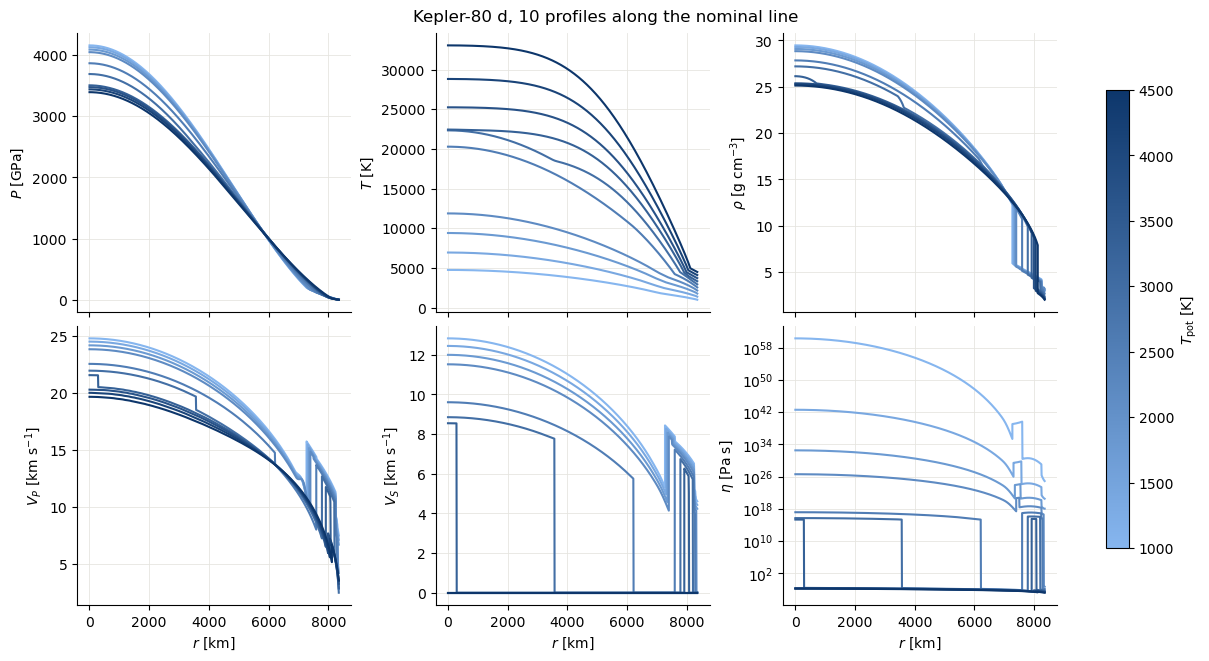

In [13]:
plot_profiles(results['Kepler-80 d'], 'Kepler-80 d, 10 profiles along the nominal line');

In the coldest profiles of Kepler-80 e both layers are solid, and $V_S$ reaches about 9 km s$^{-1}$ at the center. The core is fully liquid in the profiles from 3333 K up, and the mantle from 4111 K up, with the 3722 K mantle partly molten where its adiabat follows the melting curve. In liquid layers $V_S$ = 0 and the viscosity drops to that of the melt.

The viscosity spans nearly 50 orders of magnitude. In the cold profiles the deep mantle and the core reach $10^{30}$ to $10^{48}$ Pa s, values of Arrhenius laws evaluated far below the melting temperature. Only their size relative to the forcing period matters: the Maxwell time $\eta/\mu$ of a layer with $\eta = 10^{25}$ Pa s and $\mu = 10^{11}$ Pa is $10^{14}$ s, about 3 Myr, against the 4.6 d orbital period of Kepler-80 e, so on tidal time scales any layer above roughly $10^{25}$ Pa s responds elastically.

The phase sequence of the coldest and hottest profiles:

In [14]:
profiles_e = results['Kepler-80 e'].profiles
print(f'Coldest profile, T_pot = {profiles_e[0].T_pot:.0f} K')
display(phase_table(profiles_e[0]))
print(f'Hottest profile, T_pot = {profiles_e[-1].T_pot:.0f} K')
display(phase_table(profiles_e[-1]))

Coldest profile, T_pot = 1000 K


,layer,phase,r_top [km],r_bottom [km],P_top [GPa],P_bottom [GPa]
0,mantle,solid-en,8482.9,8389.3,0.0,4.9
1,mantle,solid-lpcen,8380.8,8363.8,5.4,6.3
2,mantle,solid-hpcen,8355.3,8270.3,6.8,11.7
3,mantle,solid-brg,8261.8,6909.7,12.2,122.9
4,mantle,solid-ppv,6901.2,4443.6,123.7,410.9
5,core,solid-epsilon-hcp,4443.6,5.0,410.9,1294.0


Hottest profile, T_pot = 4500 K


,layer,phase,r_top [km],r_bottom [km],P_top [GPa],P_bottom [GPa]
0,mantle,liquid,8482.9,5848.7,0.0,178.5
1,core,liquid,5848.7,5.0,178.5,1410.3


## 6. Planets without a rocky solution

When no Fe-MgSiO3 interior reproduces the mass and radius anywhere in the $T_\mathrm{pot}$ range, `compatible_line` and `interior_profiles` raise `NoSolutionError`. Its message names the bounding interior: the largest rocky planet of that mass (pure MgSiO3 at the hottest $T_\mathrm{pot}$) when the measured radius is too large, or the smallest (pure iron) when it is too small. When only part of the range has a solution, the line covers that part and a `UserWarning` gives the same explanation for the rest.

In [15]:
for name in ('Kepler-80 b', 'Kepler-80 c'):
    p = PLANETS[name]
    try:
        pi.compatible_line(p['mass'][0], p['radius'][0], T_POT, tables=tables)
    except pi.NoSolutionError as err:
        print(f'{name}:')
        print(textwrap.fill(str(err), 100), end='\n\n')

Kepler-80 b:
For M = 3.5 Earth masses and R = 2.3670 Earth radii, 12 of the 12 T_pot values solved from 1000 to
4500 K have no Fe-MgSiO3 solution. At those T_pot the largest rocky interior, pure MgSiO3 at T_pot =
4500 K, has R = 1.7597 Earth radii, 25.7% below the measured radius. With a pure Fe core and an
MgSiO3 mantle on an adiabat, the measured radius needs material less dense than MgSiO3, such as an
atmosphere or a volatile layer, above a smaller interior.



Kepler-80 c:
For M = 3.49 Earth masses and R = 2.5070 Earth radii, 12 of the 12 T_pot values solved from 1000 to
4500 K have no Fe-MgSiO3 solution. At those T_pot the largest rocky interior, pure MgSiO3 at T_pot =
4500 K, has R = 1.7584 Earth radii, 29.9% below the measured radius. With a pure Fe core and an
MgSiO3 mantle on an adiabat, the measured radius needs material less dense than MgSiO3, such as an
atmosphere or a volatile layer, above a smaller interior.



Even a pure MgSiO3 planet at 4500 K is about a quarter smaller than Kepler-80 b and c, so both need material less dense than rock, such as a H/He atmosphere or a water layer, above the interior. MacDonald et al. (2021) reached the same conclusion with their composition curves, which place b and c on H/He atmospheres of 1 to 2%. Volatile layers are outside the scope of this package.

## 7. A temperature jump at the core-mantle boundary

By default the adiabat runs continuously across the CMB. `dT_cmb` adds a temperature jump there, for a thermal boundary layer at the base of the mantle. A hotter core is less dense, so at fixed mass and radius the line moves to a higher CMF.

CMF shift: 0.0019 to 0.0114


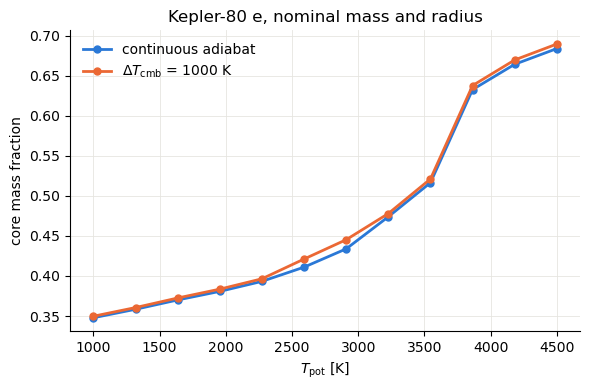

In [16]:
line_e_jump = pi.compatible_line(e['mass'][0], e['radius'][0], T_POT, dT_cmb=1000.0,
                                 tables=tables)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(line_e.T_pot, line_e.cmf, color=BLUE, marker='o', ms=5, label='continuous adiabat')
ax.plot(line_e_jump.T_pot, line_e_jump.cmf, color=ORANGE, marker='o', ms=5,
        label='$\\Delta T_\\mathrm{cmb}$ = 1000 K')
ax.set_xlabel('$T_\\mathrm{pot}$ [K]')
ax.set_ylabel('core mass fraction')
ax.set_title('Kepler-80 e, nominal mass and radius')
ax.legend(frameon=False)
fig.tight_layout()

shift = np.interp(line_e.T_pot, line_e_jump.T_pot, line_e_jump.cmf) - line_e.cmf
print(f'CMF shift: {shift.min():.4f} to {shift.max():.4f}')

A 1000 K jump raises the CMF of Kepler-80 e by 0.002 to 0.011, much less than the spread along the line or between the corner lines.

## 8. Grain size and viscosity

The viscosities of the solid silicates are diffusion-creep laws (Tackley et al. 2013, eq. 4) that scale as the grain size squared. Solid iron takes the lower of diffusion and dislocation creep, and dislocation creep does not depend on grain size. Melt viscosities depend on neither. `grain_size` (m, default 1 mm) is an argument of `integrate`, `CompatibleLine.sample`, and `interior_profiles`. Here is one Kepler-80 e profile at $T_\mathrm{pot}$ = 2000 K for three grain sizes.

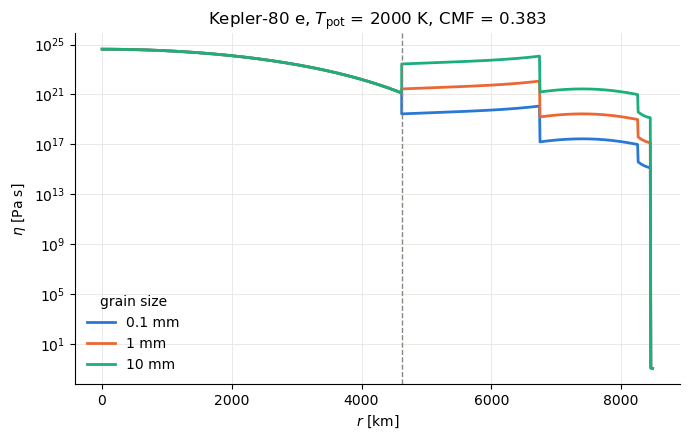

In [17]:
cmf_2000 = float(line_e.cmf_at(2000.0))
fig, ax = plt.subplots(figsize=(7, 4.5))
for d, color in zip((1e-4, 1e-3, 1e-2), (BLUE, ORANGE, AQUA)):
    p = pi.integrate(e['mass'][0], cmf_2000, 2000.0, tables=tables, grain_size=d)
    ax.plot(p.r / 1e3, p.eta, color=color, label=f'{d * 1e3:g} mm')
ax.axvline(p.R_cmb / 1e3, color='#898781', lw=1, ls='--')
ax.set_yscale('log')
ax.set_xlabel('$r$ [km]')
ax.set_ylabel(r'$\eta$ [Pa s]')
ax.set_title(f'Kepler-80 e, $T_\\mathrm{{pot}}$ = 2000 K, CMF = {cmf_2000:.3f}')
ax.legend(title='grain size', frameon=False)
fig.tight_layout()

In the solid mantle the viscosity changes by two orders of magnitude per decade of grain size. The core does not change, because for iron the grain-size-independent dislocation creep is weaker than diffusion creep for grains above about 0.05 mm. The top of the mantle is molten at this $T_\mathrm{pot}$ (MgSiO3 melts at about 1830 K at 1 bar), and the melt viscosity does not depend on grain size either.

## 9. Writing and reading the output files

`write` puts the result into a folder as plain CSV files: `summary.csv` (one row per profile), `line.csv` (the nominal line), `envelope.csv` (the two corner lines), and `profile_NNN.csv` (one radial profile each). Every file starts with `#` comment lines giving the package version, the table release and checksums, the Earth units, the inputs, and the units of each column. Profile files also list the sources of the shear modulus and viscosity laws.

In [18]:
folder = results['Kepler-80 e'].write('output/kepler80e')
print(sorted(f.name for f in folder.iterdir()))
print()
with open(folder / 'profile_000.csv') as f:
    for line in f:
        print(line.rstrip())
        if not line.startswith('#'):
            break

['envelope.csv', 'line.csv', 'profile_000.csv', 'profile_001.csv', 'profile_002.csv', 'profile_003.csv', 'profile_004.csv', 'profile_005.csv', 'profile_006.csv', 'profile_007.csv', 'profile_008.csv', 'profile_009.csv', 'summary.csv']

# Radial profile 000, surface to r = 5000 m
# paleos-interior 1.0.0
# PALEOS tables 1.3.0, doi:10.5281/zenodo.22776069
# paleos_iron_eos_table_pt.dat md5 259a2267dcf58af3b2c4dd389105b597
# paleos_mgsio3_eos_table_pt.dat md5 1f75d518bf192e66b94ec0bda190ada7
# Earth units: R_earth = 6.37810e+06 m, M_earth = 5.97217e+24 kg
# Input mass: 2.97 (-0.65, +0.76) Earth masses
# Input radius: 1.33 (-0.038, +0.039) Earth radii
# Input T_pot range: 1000 to 4500 K, dT_cmb = 0 K
# Model: Fe core under an MgSiO3 mantle, hydrostatic, adiabatic from P = 100000 Pa at T_pot
# Grain size: 0.001 m
# Melting: Anzellini et al. (2013) for Fe, Belonoshko et al. (2005) and Fei et al. (2021) for MgSiO3, as in PALEOS
# Shear modulus: Stixrude & Lithgow-Bertelloni (2024) at the PALEOS

Any CSV reader that skips `#` lines reads the files. With pandas:

In [19]:
profile = pd.read_csv(folder / 'profile_000.csv', comment='#')
profile[['r', 'P', 'T', 'rho', 'V_P', 'V_S', 'eta', 'layer', 'phase']].iloc[::100]

,r,P,T,rho,V_P,V_S,eta,layer,phase
0,8.482873e+06,1.000000e+05,1000.000000,3106.583745,7483.553272,4607.806173,7.521568e+24,mantle,solid-en
100,7.632489e+06,6.000603e+10,1325.620801,4778.979845,12841.806380,7120.348861,2.346609e+30,mantle,solid-brg
200,6.782105e+06,1.350261e+11,1559.589860,5504.563299,14583.361110,7965.534983,3.025380e+39,mantle,solid-ppv
300,5.931722e+06,2.224330e+11,1758.923478,6109.217625,16116.308940,8594.327829,7.832310e+38,mantle,solid-ppv
400,5.081338e+06,3.232316e+11,1939.016300,6677.657410,17446.935180,9114.970076,4.005442e+38,mantle,solid-ppv
500,4.239869e+06,4.730603e+11,2165.158629,15101.325120,13688.368830,6786.213964,2.878703e+41,core,solid-epsilon-hcp
600,3.391198e+06,7.284371e+11,2502.299364,16902.146680,15381.054620,7701.453941,4.012152e+44,core,solid-epsilon-hcp
700,2.542527e+06,9.579399e+11,2756.529667,18255.636200,16564.399400,8348.658105,5.118685e+46,core,solid-epsilon-hcp
800,1.693856e+06,1.138964e+12,2935.628573,19208.140590,17359.921530,8785.322818,1.193694e+48,core,solid-epsilon-hcp
900,8.451844e+05,1.254518e+12,3042.335714,19775.461400,17821.079050,9038.685657,7.110238e+48,core,solid-epsilon-hcp


With numpy alone, skip the comment block and the column-name row:

In [20]:
path = folder / 'profile_000.csv'
with open(path) as f:
    n_comment = sum(1 for line in f if line.startswith('#'))
r, P, rho = np.loadtxt(path, delimiter=',', skiprows=n_comment + 1, usecols=(0, 3, 5), unpack=True)
print(f'{len(r)} rows, r from {r[0] / 1e3:.0f} to {r[-1] / 1e3:.0f} km, '
      f'P_max = {P.max() / 1e9:.0f} GPa, rho_max = {rho.max():.0f} kg m-3')

1000 rows, r from 8483 to 5 km, P_max = 1294 GPa, rho_max = 19963 kg m-3


The functions and their arguments are documented in their docstrings (`help(pi.interior_profiles)`), and the README lists every output column with its unit.